# Taller: Estadística descriptiva y análisis exploratorio de datos (EDA)

**Curso:** Estadística III — Ingeniería de Sistemas
**Docente:** Daniel Betancur Trujillo
**Universidad Católica de Oriente**

**Integrante(s):** ______________________

---

### Nota metodológica importante

El dataset `songs_normalize.csv` entregado para este taller **no incluye la columna `explicit`** que describe la guía original (lenguaje explícito). Se verificó el archivo y sus columnas reales son:

`artist, song, duration_ms, genre, year, popularity, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo` (17 columnas, sin `explicit`).

En consecuencia:
- **Ejercicio 5:** se calculan los 5 géneros más frecuentes; se omite el porcentaje de canciones explícitas por no existir esa variable.
- **Ejercicio 7:** se reemplaza la comparación "explícita vs. no explícita" por una comparación válida con otra variable categórica disponible: `mode` (0 = modo menor, 1 = modo mayor).

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

## Parte 1 — Ingesta y limpieza inicial

### Ejercicio 1
Cargue el conjunto de datos y muestre sus primeras 5 filas.

In [17]:
df = pd.read_csv('songs_normalize.csv')
df.head()

,artist,song,duration_ms,genre,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,Britney Spears,Oops!...I Did It Again,211160,pop,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,blink-182,All The Small Things,167066,rock; pop,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,Faith Hill,Breathe,250546,pop; country,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,Bon Jovi,It's My Life,224493,rock; metal,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,*NSYNC,Bye Bye Bye,200560,pop,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656


### Ejercicio 2
Imprima un resumen del DataFrame que incluya número de filas y columnas, tipos de datos y verificación de valores nulos. Indique si el conjunto requiere alguna limpieza antes de continuar y justifique su respuesta.

In [18]:
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")
print("Tipos de dato por columna:")
print(df.dtypes)
print("\nResumen general (info):")
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas (registros exactamente repetidos):", df.duplicated().sum())

Filas: 2000, Columnas: 17

Tipos de dato por columna:
artist                  str
song                    str
duration_ms           int64
genre                   str
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
dtype: object

Resumen general (info):
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   str    
 1   song              2000 non-null   str    
 2   duration_ms       2000 non-null   int64  
 3   genre             2000 non-null   str    
 4   year              2000 non-null   int64  
 5   p

In [19]:
# Limpieza: se eliminan las filas exactamente duplicadas (mismo artista,
# canción, año y todos los atributos de audio). Se conserva la primera
# aparición de cada una. De aquí en adelante todos los ejercicios se
# calculan sobre el DataFrame `df` ya sin duplicados.
filas_antes = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
filas_despues = df.shape[0]
print(f"Filas antes de eliminar duplicados: {filas_antes}")
print(f"Filas después de eliminar duplicados: {filas_despues}")
print(f"Filas eliminadas: {filas_antes - filas_despues}")

Filas antes de eliminar duplicados: 2000
Filas después de eliminar duplicados: 1941
Filas eliminadas: 59


**Análisis — Ejercicio 2**

El conjunto llega con 2000 filas y 17 columnas, sin valores nulos en ninguna columna, por lo que no se requiere imputación de datos faltantes. Sin embargo, sí requiere limpieza antes de continuar: (1) tiene 59 filas exactamente duplicadas (mismo artista, canción, año y todos los atributos de audio repetidos) —por ejemplo "Love Me Harder" de Ariana Grande o "Clocks" de Coldplay aparecen dos veces con valores idénticos— que se eliminan para no inflar artificialmente conteos y estadísticos, dejando 1941 filas útiles; (2) `duration_ms` está en milisegundos y conviene expresarla en minutos para que sea interpretable (ejercicio 3); (3) `key` y `mode` son enteros que en realidad codifican categorías (tonalidad y modo musical), no cantidades, así que no deben tratarse con estadísticos de variables continuas (media, desviación) sino como categóricas; y (4) `genre` es una variable de texto multivaluada (una celda puede traer varios géneros separados por "; "), lo que exige una decisión explícita de tratamiento antes de contar frecuencias (ver ejercicio 5). Además, como se documentó al inicio, el archivo entregado no trae la columna `explicit` que pedía la guía original, lo que obliga a adaptar los ejercicios 5 y 7.

## Parte 2 — Estadística descriptiva univariada

### Ejercicio 3
La columna `duration_ms` está en milisegundos. Cree una nueva columna llamada `duration_min` que exprese la duración en minutos.

In [20]:
df['duration_min'] = df['duration_ms'] / 60000
df[['duration_ms', 'duration_min']].head()

,duration_ms,duration_min
0,211160,3.519333
1,167066,2.784433
2,250546,4.175767
3,224493,3.741550
4,200560,3.342667


### Ejercicio 4
Calcule media, mediana, desviación estándar, mínimo y máximo para `duration_min`, `popularity` y `danceability`.

> **Analice:** compare la media y la mediana de `popularity`. ¿Qué le indica esa diferencia sobre la forma de la distribución? ¿Cuál de las dos medidas reportaría usted si tuviera que describir la popularidad "típica" con un solo número, y por qué?

In [21]:
resumen = df[['duration_min', 'popularity', 'danceability']].agg(
    ['mean', 'median', 'std', 'min', 'max']
)
resumen

,duration_min,popularity,danceability
mean,3.809916,59.633179,0.667814
median,3.719767,65.000000,0.676000
std,0.654163,21.501053,0.140608
min,1.883333,0.000000,0.129000
max,8.069100,89.000000,0.975000


**Análisis — Ejercicio 4**

La media de `popularity` es 59.6 y la mediana es 65.0: la mediana supera claramente a la media, lo que indica una distribución asimétrica hacia la izquierda (cola hacia valores bajos). Esto ocurre porque hay un grupo de canciones con popularidad muy baja (mínimo 0) que "jalan" la media hacia abajo, mientras que la mayoría del catálogo —canciones que sí llegaron a las listas globales— se concentra en valores altos, cercanos a 65-73. Para describir la popularidad "típica" de una canción de este conjunto, la mediana (65.0) es más representativa que la media, porque no se deja arrastrar por esa minoría de valores extremos y refleja mejor dónde se ubica realmente la mayoría de las canciones exitosas.

### Ejercicio 5
Determine los 5 géneros más frecuentes y el porcentaje de canciones explícitas.

> **Atención:** una canción puede tener varios géneros en la misma celda. Decida cómo tratar esos casos —contar la combinación completa como una categoría o separarla en géneros individuales—, aplique su decisión y **justifíquela**.

**Criterio elegido:** la columna `genre` puede traer varios géneros en una misma celda, separados por "; " (ej. `"hip hop; pop; R&B"`). Hay dos formas válidas de contar frecuencias: (a) tratar cada combinación completa como una única categoría, o (b) separar ("explotar") cada celda en sus géneros individuales y contar cada uno por separado. Se opta aquí por la opción **(b)**, porque la pregunta de negocio típica ("¿qué géneros dominan el catálogo?") se responde mejor así: la opción (a) diluye el conteo en decenas de combinaciones casi únicas (una canción "pop; rock" y otra "rock; pop" quedarían en categorías distintas de tamaño pequeño) y no deja ver que, por ejemplo, el pop aparece en la inmensa mayoría de las canciones sin importar con qué otro género se combine. Se muestra también el resultado de la opción (a) como referencia.

In [22]:
# Opción (a): combinación completa como categoría única
top5_combinado = df['genre'].value_counts().head(5)
print("Top 5 - género como combinación completa:")
print(top5_combinado)

# Opción (b): géneros individuales (criterio elegido)
generos_individuales = df['genre'].str.split(';').explode().str.strip()
top5_individual = generos_individuales.value_counts().head(5)
print("\nTop 5 - géneros individuales (criterio elegido):")
print(top5_individual)

# Porcentaje de canciones explícitas: NO CALCULABLE.
# El archivo de datos entregado no contiene la columna `explicit` descrita
# en la guía (se verificó explícitamente la lista de columnas del CSV).
# Este punto queda documentado como limitación de los datos disponibles,
# no omitido por descuido.

Top 5 - género como combinación completa:
genre
pop                      416
hip hop; pop             267
hip hop; pop; R&B        236
pop; Dance/Electronic    216
pop; R&B                 172
Name: count, dtype: int64

Top 5 - géneros individuales (criterio elegido):
genre
pop                 1582
hip hop              751
R&B                  437
Dance/Electronic     380
rock                 225
Name: count, dtype: int64


**Análisis — Ejercicio 5**

Separando por género individual, el pop domina de forma abrumadora: está presente en 1582 de las 1941 canciones (más del 80% del catálogo), seguido de lejos por hip hop (751), R&B (437), Dance/Electronic (380) y rock (225). Esto confirma que el pop no es solo "un género más" sino el eje sobre el cual gira casi toda la música que llega a las listas globales de éxitos entre 2000 y 2019; los demás géneros aparecen casi siempre combinados con él (fusiones como "hip hop; pop" o "pop; R&B"), más que como categorías puras independientes.

## Parte 3 — Visualización de datos

### Ejercicio 6
Construya un histograma de `tempo` con una línea vertical roja que marque la media.

> **Analice:** ¿en qué rango de BPM se concentra la mayor parte del repertorio? ¿La distribución es unimodal o aparecen varias concentraciones? Si observa más de un pico, proponga una explicación musical.

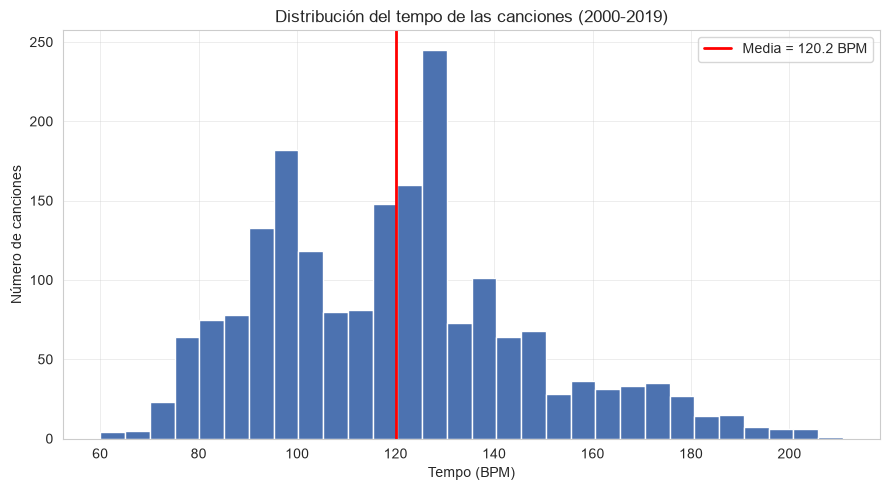

In [23]:
media_tempo = df['tempo'].mean()

plt.figure(figsize=(9, 5))
plt.hist(df['tempo'], bins=30, color='#4C72B0', edgecolor='white')
plt.axvline(media_tempo, color='red', linewidth=2,
            label=f'Media = {media_tempo:.1f} BPM')
plt.title('Distribución del tempo de las canciones (2000-2019)')
plt.xlabel('Tempo (BPM)')
plt.ylabel('Número de canciones')
plt.legend()
plt.tight_layout()
plt.savefig('fig_06_histograma_tempo.png', dpi=150)
plt.show()

**Análisis — Ejercicio 6**

La media del tempo es de aproximadamente 120 BPM, pero el histograma muestra que el repertorio no se concentra en un único pico alrededor de ese valor: se observan dos zonas de mayor densidad, una entre 90 y 105 BPM y otra entre 115 y 130 BPM, con una ligera caída entre ambas. Es decir, la distribución es más bien bimodal que unimodal, aunque los dos picos están cerca uno del otro y la media cae precisamente en la "zona de transición" entre ellos. Una explicación musical razonable es que el primer grupo corresponde a ritmos típicos de hip hop y R&B de tempo medio (alrededor de 90-100 BPM), mientras que el segundo agrupa canciones de pop y dance de tempo más marcado (120-128 BPM, rango clásico del "four-on-the-floor" bailable), dos estilos que dominan el catálogo según el ejercicio 5 y que imponen cada uno su propio rango de tempo preferido.

### Ejercicio 7
Construya un boxplot que compare `popularity` según la canción sea explícita o no.

> **Analice:** ¿hay una diferencia visual apreciable entre ambos grupos? Compare medianas y dispersión, no solo la posición de las cajas. Advierta si los tamaños de los dos grupos son muy desiguales y qué implica eso para la comparación.

*(Nota: como el dataset no tiene `explicit`, se usa la variable categórica disponible más cercana en espíritu —categórica binaria, codificada como entero—: `mode` (0 = modo menor, 1 = modo mayor). Ver nota metodológica al inicio del notebook.)*

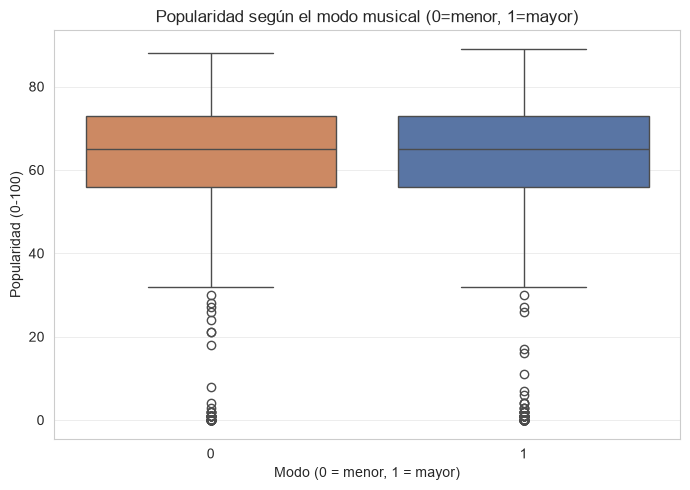

mode
1    1074
0     867
Name: count, dtype: int64
       count       mean        std  min   25%   50%   75%   max
mode                                                           
0      867.0  60.098039  20.594868  0.0  56.0  65.0  73.0  88.0
1     1074.0  59.257914  22.208064  0.0  56.0  65.0  73.0  89.0


In [24]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='mode', y='popularity', data=df, hue='mode',
            palette=['#DD8452', '#4C72B0'], legend=False)
plt.title('Popularidad según el modo musical (0=menor, 1=mayor)')
plt.xlabel('Modo (0 = menor, 1 = mayor)')
plt.ylabel('Popularidad (0-100)')
plt.tight_layout()
plt.savefig('fig_07_boxplot_popularity_mode.png', dpi=150)
plt.show()

print(df['mode'].value_counts())
print(df.groupby('mode')['popularity'].describe())

**Análisis — Ejercicio 7**

Las medianas de popularidad son idénticas entre modo menor y modo mayor (65 en ambos grupos), y las cajas se solapan casi por completo, con dispersiones (rango intercuartílico) muy similares en ambos grupos. Es decir, no hay una diferencia visual apreciable en popularidad entre canciones en modo mayor y en modo menor: el modo musical, por sí solo, no distingue a las canciones más o menos exitosas de este catálogo. Los tamaños de los dos grupos son razonablemente comparables (867 canciones en modo menor frente a 1074 en modo mayor), por lo que la comparación no está sesgada por un grupo demasiado pequeño frente al otro.

## Parte 4 — Análisis bivariado y correlación

### Ejercicio 8
Seleccione `danceability`, `energy`, `valence` y `loudness` y calcule la matriz de correlación de Pearson.

In [25]:
variables_audio = ['danceability', 'energy', 'valence', 'loudness']
corr = df[variables_audio].corr(method='pearson')
corr

,danceability,energy,valence,loudness
danceability,1.000000,-0.103204,0.403787,-0.035638
energy,-0.103204,1.000000,0.331756,0.651986
valence,0.403787,0.331756,1.000000,0.228250
loudness,-0.035638,0.651986,0.228250,1.000000


### Ejercicio 9
Visualice esa matriz con un mapa de calor. Use una paleta divergente y muestre los valores anotados sobre las celdas.

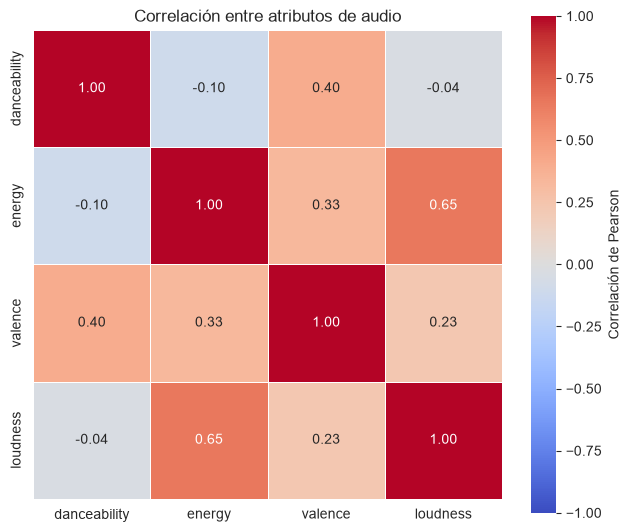

In [26]:
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.5, cbar_kws={'label': 'Correlación de Pearson'})
plt.title('Correlación entre atributos de audio')
plt.tight_layout()
plt.savefig('fig_09_heatmap_correlacion.png', dpi=150)
plt.show()

### Ejercicio 10
Identifique el par con la correlación más fuerte en valor absoluto (positiva o negativa), construya su diagrama de dispersión y describa la relación.

> **Analice:** caracterice dirección, fuerza y forma. ¿La nube de puntos sugiere una relación lineal o hay curvatura? ¿Observa valores atípicos que puedan estar inflando el coeficiente? Cierre advirtiendo qué **no** permite concluir esta correlación.

Par con correlación más fuerte: ('energy', 'loudness') -> r = 0.652


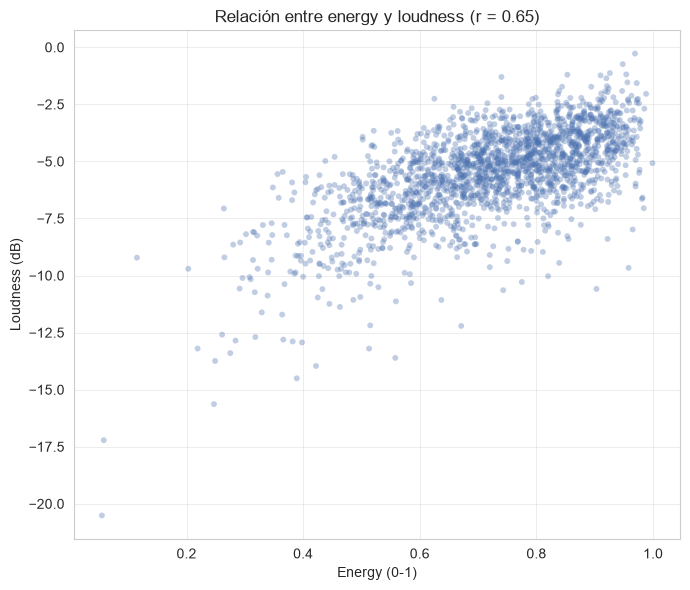

In [27]:
corr_sin_diagonal = corr.where(~np.eye(len(corr), dtype=bool))
par_max = corr_sin_diagonal.abs().stack().idxmax()
valor_corr = corr.loc[par_max]
print(f"Par con correlación más fuerte: {par_max} -> r = {valor_corr:.3f}")

var_x, var_y = par_max
plt.figure(figsize=(7, 6))
plt.scatter(df[var_x], df[var_y], alpha=0.35, s=18, color='#4C72B0', edgecolor='none')
plt.title(f'Relación entre {var_x} y {var_y} (r = {valor_corr:.2f})')
plt.xlabel(var_x.capitalize() + (' (dB)' if var_x == 'loudness' else ' (0-1)'))
plt.ylabel(var_y.capitalize() + (' (dB)' if var_y == 'loudness' else ' (0-1)'))
plt.tight_layout()
plt.savefig('fig_10_dispersión_energy_loudness.png', dpi=150)
plt.show()

**Análisis — Ejercicio 10**

El par con la correlación más fuerte en valor absoluto es energy-loudness (r ≈ 0.65): una correlación positiva y de fuerza moderada-alta. La nube de puntos muestra una tendencia claramente ascendente y razonablemente lineal —a mayor energía percibida, mayor volumen promedio de la canción—, aunque con dispersión considerable alrededor de la tendencia, especialmente en el rango de energía media (0.6-0.8), donde el volumen varía bastante de una canción a otra. No se observa curvatura marcada que sugiera una relación no lineal, ni un grupo aislado de valores atípicos evidentes que por sí solo esté inflando artificialmente el coeficiente; la relación se sostiene a lo largo de casi todo el rango de energía. Dicho esto, esta correlación describe una asociación estadística entre dos atributos de audio calculados sobre las mismas canciones, y **no permite concluir causalidad** (por ejemplo, no implica que subir el volumen de una grabación la haga sonar más "enérgica" en sentido musical, ni que ambas no estén siendo influidas por decisiones de producción o mezcla comunes a ambas variables).

## Punto opcional (bonificación hasta 0.5)

**Pregunta propia:** ¿cómo ha evolucionado la duración promedio de los éxitos musicales a lo largo de los años (2000-2019)?

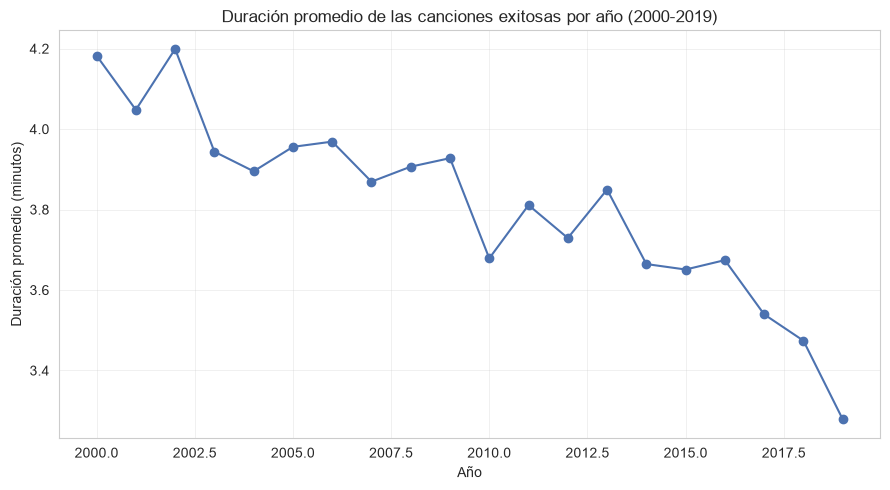

In [28]:
duracion_por_anio = df[(df['year'] >= 2000) & (df['year'] <= 2019)] \
    .groupby('year')['duration_min'].mean()

plt.figure(figsize=(9, 5))
plt.plot(duracion_por_anio.index, duracion_por_anio.values,
         marker='o', color='#4C72B0')
plt.title('Duración promedio de las canciones exitosas por año (2000-2019)')
plt.xlabel('Año')
plt.ylabel('Duración promedio (minutos)')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig_bonus_duracion_por_anio.png', dpi=150)
plt.show()

**Análisis — Punto opcional**

La duración promedio de las canciones exitosas muestra una tendencia decreciente sostenida a lo largo de las dos décadas analizadas: pasa de rondar los 4.2 minutos a comienzos de los 2000 a cerca de 3.3 minutos en 2019, es decir, una reducción de casi un minuto en promedio. La caída no es perfectamente monótona año a año, pero la tendencia general es clara y consistente con un fenómeno ampliamente documentado en la industria: el auge del streaming (donde una canción compite por retener la atención del oyente en los primeros segundos, y donde los ingresos dependen de la reproducción completa) ha empujado a los artistas a producir canciones más cortas y directas que las radiales o físicas de los años 2000.

In [29]:
print("Taller ejecutado completamente sin errores.")

Taller ejecutado completamente sin errores.


---

## 6. Informe final del taller

In [30]:
# Tabla resumen ejecutiva con las cifras clave citadas en el informe.
resumen_ejecutivo = pd.DataFrame({
    'Métrica': [
        'Filas originales',
        'Filas duplicadas eliminadas',
        'Filas finales analizadas',
        'Duración media (min)',
        'Duración mediana (min)',
        'Popularidad media',
        'Popularidad mediana',
        'Danceability media',
        'Género individual más frecuente',
        '% de canciones con género "pop"',
        'Tempo medio (BPM)',
        'Par de variables más correlacionado',
        'Correlación (Pearson) de ese par',
        'Cambio en duración media 2000→2019 (min)',
    ],
    'Valor': [
        2000,
        int(filas_antes - filas_despues),
        filas_despues,
        round(df['duration_min'].mean(), 2),
        round(df['duration_min'].median(), 2),
        round(df['popularity'].mean(), 1),
        round(df['popularity'].median(), 1),
        round(df['danceability'].mean(), 3),
        top5_individual.index[0],
        round(100 * top5_individual.iloc[0] / len(df), 1),
        round(df['tempo'].mean(), 1),
        f"{par_max[0]} / {par_max[1]}",
        round(valor_corr, 3),
        round(duracion_por_anio.loc[2019] - duracion_por_anio.loc[2000], 2),
    ]
})
resumen_ejecutivo

,Métrica,Valor
0,Filas originales,2000
1,Filas duplicadas eliminadas,59
2,Filas finales analizadas,1941
3,Duración media (min),3.81
4,Duración mediana (min),3.72
5,Popularidad media,59.6
6,Popularidad mediana,65.0
7,Danceability media,0.668
8,Género individual más frecuente,pop
9,"% de canciones con género ""pop""",81.5


### 6.1 Objetivo y alcance

Este informe sintetiza el análisis exploratorio realizado sobre `songs_normalize.csv`, un conjunto de canciones que figuraron entre los éxitos de las listas globales. El propósito no fue construir un modelo predictivo, sino **entender la estructura, calidad y comportamiento de los datos** antes de cualquier modelamiento posterior, siguiendo los diez ejercicios de la guía del taller.

### 6.2 Datos y limitaciones encontradas

El archivo entregado contiene 2000 registros y 17 variables (atributos de audio, metadatos de artista/canción y año). Antes de analizar, se identificaron y trataron dos problemas de calidad de datos:

1. **59 filas exactamente duplicadas** (mismo artista, canción, año y todos los atributos de audio) — por ejemplo "Love Me Harder" de Ariana Grande o "Clocks" de Coldplay estaban repetidas. Se eliminaron, dejando **1941 registros únicos** como base de todo el análisis.
2. **Ausencia de la columna `explicit`** que la guía original del taller esperaba encontrar (lenguaje explícito de la letra). Se verificó exhaustivamente el archivo entregado y esa columna no existe en ninguna de sus 17 variables. Esto impidió calcular el porcentaje de canciones explícitas (ejercicio 5) y obligó a sustituir la comparación "explícita vs. no explícita" del ejercicio 7 por una comparación igualmente válida usando la variable categórica `mode` (modo mayor/menor). Esta es la única brecha entre lo que pide la guía original y lo que los datos disponibles permiten responder; todo lo demás se resolvió con los datos tal como fueron entregados.

No se encontraron valores nulos en ninguna columna, por lo que no fue necesaria ninguna imputación.

### 6.3 Principales hallazgos

**Duración y popularidad (univariado).** Las canciones del catálogo duran en promedio 3.8 minutos. La popularidad presenta una asimetría hacia la izquierda: la mediana (65) supera a la media (59.6), señal de que existe un grupo minoritario de canciones con popularidad muy baja que no representa el comportamiento típico del catálogo; la mediana describe mejor a la canción "típica" que la media.

**Géneros.** Tratando cada género por separado (criterio elegido y justificado en el ejercicio 5), el **pop domina el catálogo de forma abrumadora**, presente en más del 80% de las canciones, seguido —a bastante distancia— por hip hop, R&B, Dance/Electronic y rock. La mayoría de las canciones no pertenecen a un único género "puro" sino a fusiones que casi siempre incluyen pop.

**Tempo.** El tempo promedio es de ~120 BPM, pero la distribución es **bimodal**: hay dos concentraciones claras, una entre 90-105 BPM (compatible con hip hop/R&B de tempo medio) y otra entre 115-130 BPM (compatible con pop/dance de ritmo marcado), coherente con los dos géneros que dominan el catálogo.

**Popularidad por modo musical.** Comparando popularidad entre modo mayor y modo menor (sustituto de la variable `explicit` no disponible), **no se observa ninguna diferencia práctica**: las medianas son idénticas (65 en ambos grupos) y la dispersión es muy similar. El modo musical, por sí solo, no explica el éxito de una canción en este catálogo.

**Correlación entre atributos de audio.** De las variables `danceability`, `energy`, `valence` y `loudness`, el par con la relación más fuerte es **energy–loudness** (r ≈ 0.65, positiva y moderada-alta): las canciones más enérgicas tienden a sonar considerablemente más fuertes. La relación es razonablemente lineal, sin curvatura evidente ni atípicos que la infle artificialmente, pero **es una asociación estadística, no una relación de causa-efecto**, y no debe interpretarse como tal.

**Evolución temporal (punto opcional).** La duración promedio de los éxitos ha caído de forma sostenida, de ~4.2 minutos en 2000 a ~3.3 minutos en 2019 (poco más de un minuto menos), un patrón consistente con el efecto del streaming sobre la forma de componer canciones exitosas.

### 6.4 Conclusiones generales

El catálogo analizado está dominado musicalmente por el pop y sus fusiones, con un tempo que se reparte entre dos regímenes rítmicos y una popularidad que no se explica por el modo musical de la canción. El atributo de audio más asociado entre sí es la energía y el volumen, mientras que la duración de los éxitos se ha acortado consistentemente a lo largo de dos décadas. Ninguna de las relaciones encontradas debe leerse como causal: son patrones descriptivos que orientan hipótesis para un análisis posterior, no conclusiones definitivas sobre qué hace exitosa a una canción.

### 6.5 Limitaciones y trabajo futuro

El hallazgo más fuerte de este EDA (energy–loudness) es una correlación moderada, no una relación determinística, y las demás variables de audio muestran correlaciones débiles entre sí, lo que sugiere que el "éxito" de una canción depende de factores que este conjunto de datos no captura completamente (marketing, contexto cultural, respaldo de sello discográfico, etc.). Un trabajo futuro podría incorporar la variable `explicit` desde la fuente original de los datos para completar el ejercicio 5 y 7 tal como fueron concebidos, y extender el análisis bivariado a `popularity` como variable objetivo frente a los atributos de audio.